# CH15 – Road Safety Insight: Understand Accidents. Discover Risk Patterns. Support Safer Roads.
## Data Science Skill-Based Assessment

### 1. Problem Statement and Objectives

**Objective:**  
Analyze road traffic accident records, detect data quality defects, integrate heterogeneous multi-table datasets, discover empirical patterns associated with accident frequency and severity, train a machine learning classification model to predict injury severity, and deliver actionable evidence-based recommendations for municipal road safety improvement.

**Project Scope & Workflow:**
1. **Data Understanding & Quality Assessment**: Profile 5 synthetic raw tables (`accidents.csv`, `roads.csv`, `weather.csv`, `traffic.csv`, `vehicles.csv`), detecting intentionally planted duplicates, missingness, and outliers.
2. **Data Cleaning & Integration**: Deduplicate incident records, filter invalid target labels, impute missing values, standardize categorical fields, treat outliers, and execute verified 1-to-1 inner joins.
3. **Exploratory Data Analysis (EDA)**: Examine empirical crash distributions across severity tiers, urban locations, temporal windows, weather conditions, road types, junctions, and vehicle categories.
4. **Feature Engineering**: Construct derived temporal attributes (`hour_of_day`, `day_of_week`, `time_period`, `is_weekend`) and prevent target leakage.
5. **Machine Learning Model Development**: Implement a `ColumnTransformer` preprocessing pipeline and train a `RandomForestClassifier` with balanced class weights using a strict stratified 80/20 train-test partition.
6. **Model Evaluation & Interpretation**: Measure out-of-sample Accuracy, Macro F1, Weighted F1, class-wise metrics, confusion matrix, and feature importances.
7. **Business Insights & Decision Support**: Formulate strategic road safety interventions grounded strictly in empirical findings.

> **Important Synthetic Data Disclaimer:**  
> All data analyzed in this notebook is computer-generated synthetic educational data. Location names and metrics do not reflect actual real-world casualties or municipal crash statistics. Because exposure denominators (vehicle-kilometers travelled, baseline non-crash traffic flows) are not present, findings reflect relative incident associations rather than physical crash causation or absolute per-km risk rates.

### 2. Imports and Configuration

Set up analysis environment, configure matplotlib/seaborn plotting aesthetics, and define relative directory paths.

In [1]:
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
notebook_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(notebook_dir, ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Modeling libraries
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib

# Plotting configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

print("Environment configured successfully. Project root:", project_root)

Environment configured successfully. Project root: V:\Project\DS SAT 2


### 3. Dataset Loading and Initial Inspection

Load all 5 raw datasets (`accidents.csv`, `roads.csv`, `weather.csv`, `traffic.csv`, `vehicles.csv`) and inspect shapes, column types, and initial records.

In [2]:
raw_dir = os.path.join(project_root, "data", "raw")

df_acc_raw = pd.read_csv(os.path.join(raw_dir, "accidents.csv"))
df_roads_raw = pd.read_csv(os.path.join(raw_dir, "roads.csv"))
df_weath_raw = pd.read_csv(os.path.join(raw_dir, "weather.csv"))
df_traf_raw = pd.read_csv(os.path.join(raw_dir, "traffic.csv"))
df_veh_raw = pd.read_csv(os.path.join(raw_dir, "vehicles.csv"))

raw_summary = pd.DataFrame({
    "Dataset": ["accidents.csv", "roads.csv", "weather.csv", "traffic.csv", "vehicles.csv"],
    "Rows": [len(df_acc_raw), len(df_roads_raw), len(df_weath_raw), len(df_traf_raw), len(df_veh_raw)],
    "Columns": [len(df_acc_raw.columns), len(df_roads_raw.columns), len(df_weath_raw.columns), len(df_traf_raw.columns), len(df_veh_raw.columns)],
    "Unique IDs": [df_acc_raw["incident_id"].nunique(), df_roads_raw["incident_id"].nunique(), df_weath_raw["incident_id"].nunique(), df_traf_raw["incident_id"].nunique(), df_veh_raw["incident_id"].nunique()],
    "Total Missing Cells": [df_acc_raw.isnull().sum().sum(), df_roads_raw.isnull().sum().sum(), df_weath_raw.isnull().sum().sum(), df_traf_raw.isnull().sum().sum(), df_veh_raw.isnull().sum().sum()]
})
display(raw_summary)

,Dataset,Rows,Columns,Unique IDs,Total Missing Cells
0,accidents.csv,6040,5,6000,151
1,roads.csv,6000,4,6000,0
2,weather.csv,6000,4,6000,1063
3,traffic.csv,6000,3,6000,0
4,vehicles.csv,6000,3,6000,0


### 4. Data Quality Assessment

Perform a granular audit across all five raw files to detect and document the intentionally planted data quality issues.

In [3]:
from src.data_processing import assess_data_quality

report_df, raw_dfs = assess_data_quality(raw_dir=raw_dir)
print(f"Data Quality Report contains {len(report_df)} column assessments:")
display(report_df[["Dataset", "Column", "Data_Type", "Total_Rows", "Null_Count", "Null_Pct", "Unique_Values", "Quality_Notes"]])

[INFO] Data quality assessment complete. Report saved to V:\Project\DS SAT 2\data\processed\data_quality_report.csv
Data Quality Report contains 19 column assessments:


,Dataset,Column,Data_Type,Total_Rows,Null_Count,Null_Pct,Unique_Values,Quality_Notes
0,accidents.csv,incident_id,object,6040,0,0.00,6000,None detected
1,accidents.csv,date,object,6040,0,0.00,731,None detected
2,accidents.csv,time,object,6040,0,0.00,1184,None detected
3,accidents.csv,location,object,6040,151,2.50,20,151 missing locations
4,accidents.csv,severity,object,6040,0,0.00,7,"Invalid labels: {'Unknown': 8, 'Critical': 6, ..."
5,roads.csv,incident_id,object,6000,0,0.00,6000,None detected
6,roads.csv,road_type,object,6000,0,0.00,21,16 case/whitespace variations (21 raw vs 5 sta...
7,roads.csv,junction_type,object,6000,0,0.00,6,None detected
8,roads.csv,speed_limit_kmph,int64,6000,0,0.00,24,"18 invalid speed limits outside [20, 80] km/h ..."
9,weather.csv,incident_id,object,6000,0,0.00,6000,None detected


### 5. Preprocessing and Cleaning

Execute data cleaning rules:
1. Deduplicate `accidents.csv` by `incident_id` (40 duplicate rows).
2. Validate `severity` against valid classes (`Minor`, `Serious`, `Fatal`) and filter 24 invalid entries.
3. Impute 149 missing locations with `'Unknown Location'` to preserve accident records.
4. Normalize `road_type` whitespace and casing to standard 5 categories.
5. Impute invalid speed limits (`<= 0` or `> 120` km/h) using road-type median.
6. Impute 300 blank weather rows with mode (`'Clear'`) and median rainfall/visibility.
7. Correct extreme traffic volume outliers (`<= 0` or `> 10,000` vph) using road-type and peak-flag grouped medians.

In [4]:
from src.data_processing import clean_and_integrate_data

df_clean, audit_log = clean_and_integrate_data(
    raw_dir=raw_dir,
    output_dir=os.path.join(project_root, "data", "processed")
)
print("Data Cleaning Pipeline Execution Successful.")
print(f"Cleaned dataset shape: {df_clean.shape}")

[INFO] Cleaned dataset saved to V:\Project\DS SAT 2\data\processed\cleaned_accidents.csv (5976 records)

DATA CLEANING AUDIT REPORT
Raw accidents records:            6040
Duplicates removed:                40
Invalid severity records removed:  24
Missing locations imputed:         149
Road type labels standardized:     115
Speed limit outliers imputed:      18
Missing weather records imputed:   300
Traffic volume outliers imputed:   24
Final Cleaned Dataset Records:     5976

Data Cleaning Pipeline Execution Successful.
Cleaned dataset shape: (5976, 23)


### 6. Dataset Merging and Validation

Verify join cardinality across the five merged tables to ensure zero unintended record multiplication and 100% key integrity.

In [5]:
print("Cleaned Dataset Head (First 3 Records):")
display(df_clean.head(3))

print("\nVerification Checks:")
print(f"Total Unique incident_ids: {df_clean['incident_id'].nunique()} (Matches total rows: {len(df_clean) == df_clean['incident_id'].nunique()})")
print(f"Null values in cleaned dataset:\n{df_clean.isnull().sum()[df_clean.isnull().sum() > 0]}")
print(f"Target Severity Distribution:\n{df_clean['severity'].value_counts()}")

Cleaned Dataset Head (First 3 Records):


,incident_id,date,time,location,severity,road_type,junction_type,speed_limit_kmph,rainfall_mm,visibility_km,weather_condition,traffic_volume_vph,peak_flag,vehicle_category,vehicle_count,hour_of_day,day_of_week,day_of_week_num,month,month_name,is_weekend,time_period,is_severe
0,RSA000036,2025-03-10,08:30,Railway Station Approach,Minor,Service Road,Unsignalized Intersection,30,0.00,10.00,Clear,1771,Peak,Motorcycle,1,8,Monday,0,3,March,0,Morning,0
1,RSA003116,2025-09-11,17:39,Tech Park Boulevard,Minor,Service Road,Signalized Intersection,30,0.06,9.55,Clear,1454,Peak,Motorcycle,2,17,Thursday,3,9,September,0,Evening,0
2,RSA003551,2024-05-05,20:43,Hospital Access Road,Minor,Urban Arterial,T-Junction,40,0.08,2.77,Fog,4490,Peak,Car,1,20,Sunday,6,5,May,1,Evening,0



Verification Checks:
Total Unique incident_ids: 5976 (Matches total rows: True)
Null values in cleaned dataset:
Series([], dtype: int64)
Target Severity Distribution:
severity
Minor      4100
Serious    1645
Fatal       231
Name: count, dtype: int64


### 7. Exploratory Data Analysis (EDA) and Visualizations

Investigate key relationships across the 5,976 cleaned accident records:
- Accident volume & severity class breakdown
- Spatial distribution and severe accident corridors
- Hourly and day-of-week accident trends
- Weather conditions & visibility risks
- Road classifications and nominal speed limits
- Primary vehicle types involved and vulnerability

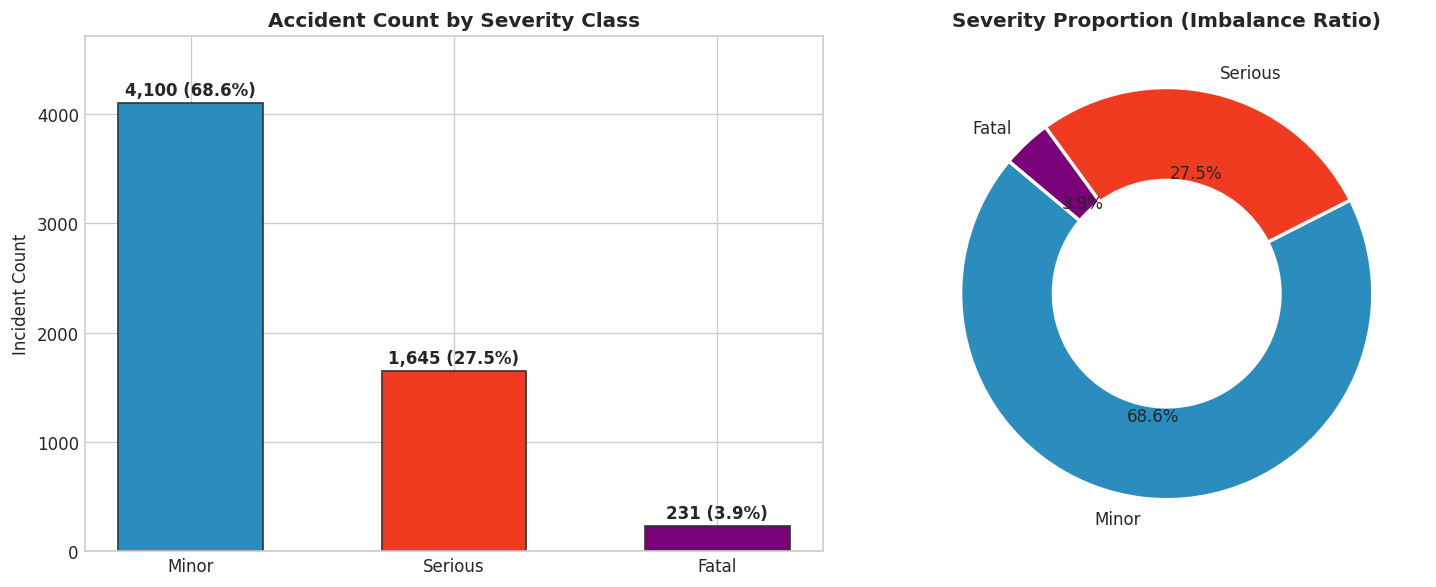

In [6]:
# Severity Distribution Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
sev_counts = df_clean["severity"].value_counts()[["Minor", "Serious", "Fatal"]]
colors = ["#2b8cbe", "#f03b20", "#7a0177"]

bars = ax1.bar(sev_counts.index, sev_counts.values, color=colors, width=0.55, edgecolor="#333")
ax1.set_title("Accident Count by Severity Class", fontsize=12, fontweight="bold")
ax1.set_ylabel("Incident Count")
for b in bars:
    y = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2., y + 40, f"{y:,} ({y/len(df_clean)*100:.1f}%)", ha="center", va="bottom", fontweight="bold")
ax1.set_ylim(0, max(sev_counts.values)*1.15)

ax2.pie(sev_counts.values, labels=sev_counts.index, colors=colors, autopct="%1.1f%%", startangle=140,
        wedgeprops=dict(width=0.45, edgecolor="w", linewidth=2))
ax2.set_title("Severity Proportion (Imbalance Ratio)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

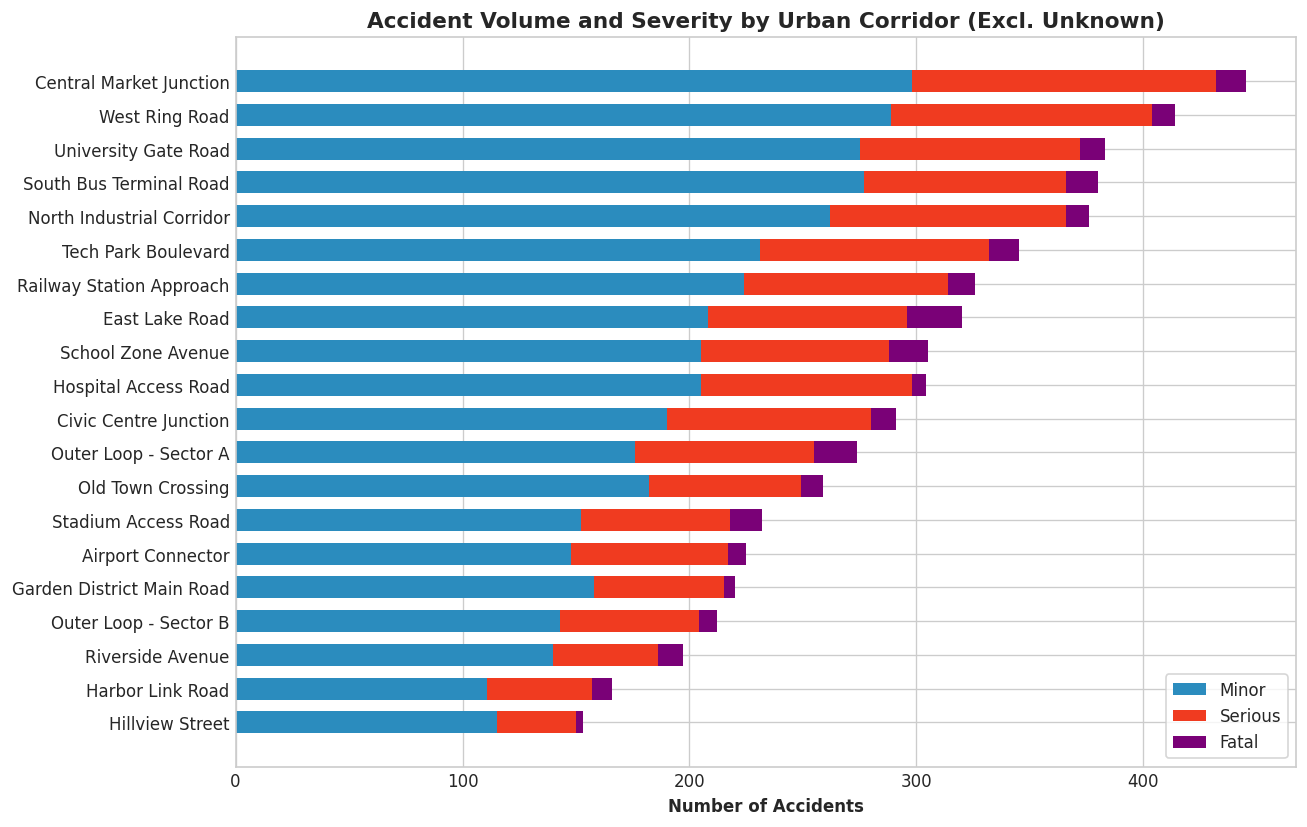

In [7]:
# Location Hotspot Analysis
plt.figure(figsize=(11, 7))
loc_df = df_clean[df_clean["location"] != "Unknown Location"].groupby("location")["severity"].value_counts().unstack().fillna(0)
loc_df["Total"] = loc_df.sum(axis=1)
loc_df = loc_df.sort_values(by="Total", ascending=True)

y_pos = np.arange(len(loc_df))
plt.barh(y_pos, loc_df["Minor"], color="#2b8cbe", label="Minor", height=0.65)
plt.barh(y_pos, loc_df.get("Serious", 0), left=loc_df["Minor"], color="#f03b20", label="Serious", height=0.65)
plt.barh(y_pos, loc_df.get("Fatal", 0), left=loc_df["Minor"] + loc_df.get("Serious", 0), color="#7a0177", label="Fatal", height=0.65)

plt.yticks(y_pos, loc_df.index)
plt.xlabel("Number of Accidents", fontweight="bold")
plt.title("Accident Volume and Severity by Urban Corridor (Excl. Unknown)", fontsize=13, fontweight="bold")
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

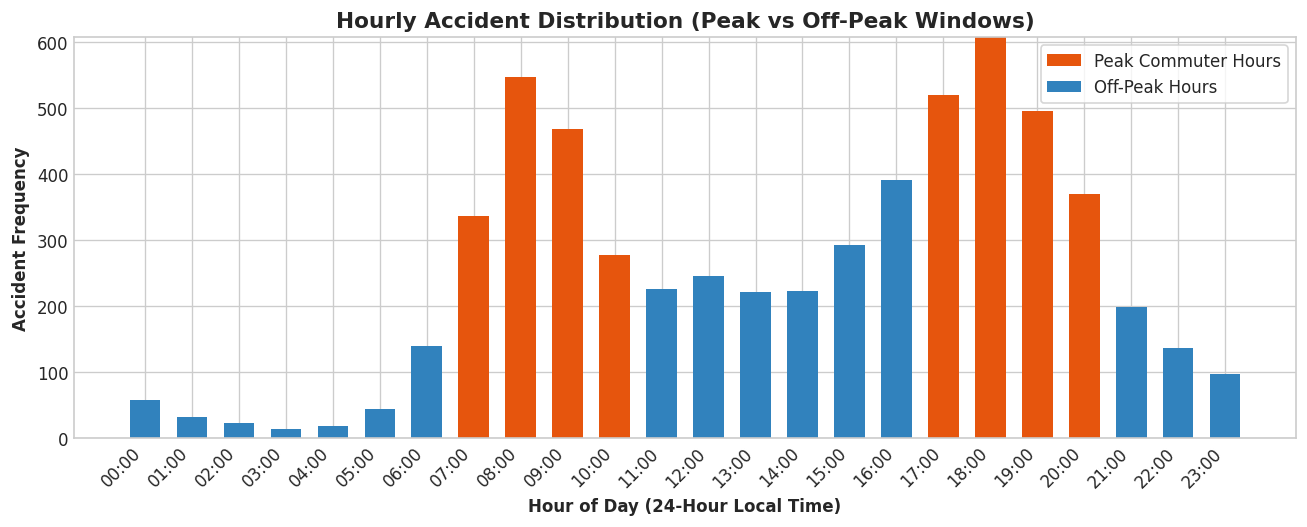

In [8]:
# Hourly Trend & Peak Commuter Distribution
plt.figure(figsize=(11, 4.5))
hourly_peak = df_clean.groupby(["hour_of_day", "peak_flag"]).size().unstack().fillna(0)
hours = np.arange(24)

plt.bar(hours, hourly_peak.get("Peak", 0), label="Peak Commuter Hours", color="#e6550d", width=0.65)
plt.bar(hours, hourly_peak.get("Off-Peak", 0), bottom=hourly_peak.get("Peak", 0), label="Off-Peak Hours", color="#3182bd", width=0.65)

plt.xticks(hours, [f"{h:02d}:00" for h in hours], rotation=45, ha="right")
plt.xlabel("Hour of Day (24-Hour Local Time)", fontweight="bold")
plt.ylabel("Accident Frequency", fontweight="bold")
plt.title("Hourly Accident Distribution (Peak vs Off-Peak Windows)", fontsize=13, fontweight="bold")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

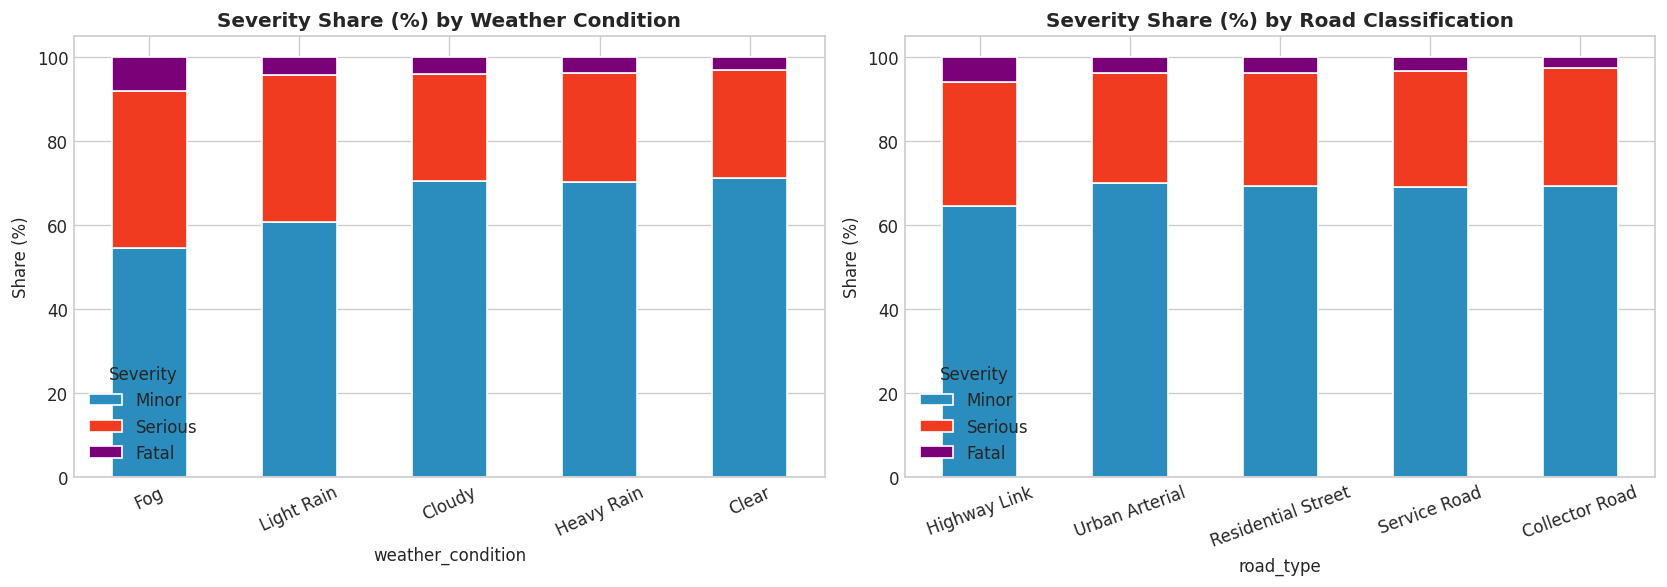

In [9]:
# Weather Condition and Road Type Cross-Tabs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

weath_pct = pd.crosstab(df_clean["weather_condition"], df_clean["severity"], normalize="index")[["Minor", "Serious", "Fatal"]] * 100
weath_pct.sort_values(by="Fatal", ascending=False).plot(kind="bar", stacked=True, color=colors, ax=ax1, edgecolor="w")
ax1.set_title("Severity Share (%) by Weather Condition", fontsize=12, fontweight="bold")
ax1.set_ylabel("Share (%)")
ax1.tick_params(axis="x", rotation=25)
ax1.legend(title="Severity")

road_pct = pd.crosstab(df_clean["road_type"], df_clean["severity"], normalize="index")[["Minor", "Serious", "Fatal"]] * 100
road_pct.sort_values(by="Fatal", ascending=False).plot(kind="bar", stacked=True, color=colors, ax=ax2, edgecolor="w")
ax2.set_title("Severity Share (%) by Road Classification", fontsize=12, fontweight="bold")
ax2.set_ylabel("Share (%)")
ax2.tick_params(axis="x", rotation=20)
ax2.legend(title="Severity")

plt.tight_layout()
plt.show()

### 8. Feature Engineering

Extract predictive features while strictly excluding identifiers (`incident_id`), timestamps (`date`, `time`), and target-derived indicators (`is_severe`).

In [10]:
from src.feature_engineering import prepare_features, NUMERICAL_FEATURES, CATEGORICAL_FEATURES

X, y, feature_meta = prepare_features(df_clean)

print("Feature Engineering Verification:")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Numerical Features ({len(NUMERICAL_FEATURES)}): {NUMERICAL_FEATURES}")
print(f"Categorical Features ({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")
display(X.head(3))

Feature Engineering Verification:
X shape: (5976, 16)
y shape: (5976,)
Numerical Features (8): ['hour_of_day', 'month', 'is_weekend', 'speed_limit_kmph', 'rainfall_mm', 'visibility_km', 'traffic_volume_vph', 'vehicle_count']
Categorical Features (8): ['day_of_week', 'time_period', 'location', 'road_type', 'junction_type', 'weather_condition', 'peak_flag', 'vehicle_category']


,hour_of_day,month,is_weekend,speed_limit_kmph,rainfall_mm,visibility_km,traffic_volume_vph,vehicle_count,day_of_week,time_period,location,road_type,junction_type,weather_condition,peak_flag,vehicle_category
0,8,3,0,30,0.00,10.00,1771,1,Monday,Morning,Railway Station Approach,Service Road,Unsignalized Intersection,Clear,Peak,Motorcycle
1,17,9,0,30,0.06,9.55,1454,2,Thursday,Evening,Tech Park Boulevard,Service Road,Signalized Intersection,Clear,Peak,Motorcycle
2,20,5,1,40,0.08,2.77,4490,1,Sunday,Evening,Hospital Access Road,Urban Arterial,T-Junction,Fog,Peak,Car


### 9. Train-Test Splitting and Preprocessing Pipeline

Split dataset using a stratified 80/20 partition to preserve class distribution across folds. Configure `ColumnTransformer` with `SimpleImputer`, `StandardScaler`, and `OneHotEncoder(handle_unknown='ignore')`.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training partition size: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Testing partition size:  {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

print("\nClass Proportions in Train Set:")
print(y_train.value_counts(normalize=True).round(4))

print("\nClass Proportions in Test Set:")
print(y_test.value_counts(normalize=True).round(4))

# Build ColumnTransformer
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, NUMERICAL_FEATURES),
        ("cat", cat_pipeline, CATEGORICAL_FEATURES)
    ],
    remainder="drop"
)
print("\nColumnTransformer defined successfully.")

Training partition size: 4780 (80.0%)
Testing partition size:  1196 (20.0%)

Class Proportions in Train Set:
severity
Minor      0.6860
Serious    0.2753
Fatal      0.0387
Name: proportion, dtype: float64

Class Proportions in Test Set:
severity
Minor      0.6865
Serious    0.2751
Fatal      0.0385
Name: proportion, dtype: float64

ColumnTransformer defined successfully.


### 10. Random Forest Model Training

Integrate preprocessing and `RandomForestClassifier` into an end-to-end `Pipeline`. Apply `class_weight='balanced'` to prevent majority-class collapse on the 3.9% fatal minority class. Fit strictly on training partition.

In [12]:
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

full_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

print("Fitting pipeline on X_train...")
full_pipeline.fit(X_train, y_train)
print("Pipeline fitting complete.")

Fitting pipeline on X_train...


Pipeline fitting complete.


### 11. Model Evaluation

Evaluate fitted pipeline on untouched test set ($N=1,196$). Compute Accuracy, Macro F1, Weighted F1, class-wise precision/recall, confusion matrix, and execute automated consistency checks.

OUT-OF-SAMPLE TEST EVALUATION METRICS
Overall Accuracy:  0.6338 (63.38%)
Macro F1-Score:    0.3670
Weighted F1-Score: 0.6027

Classification Report:

              precision    recall  f1-score   support

       Fatal     0.1053    0.0435    0.0615        46
       Minor     0.7086    0.8295    0.7643       821
     Serious     0.3472    0.2280    0.2752       329

    accuracy                         0.6338      1196
   macro avg     0.3870    0.3670    0.3670      1196
weighted avg     0.5860    0.6338    0.6027      1196

Automated Checks PASSED: Confusion-matrix row sums equal true class supports, column sums equal predicted counts, and total equals test set size.


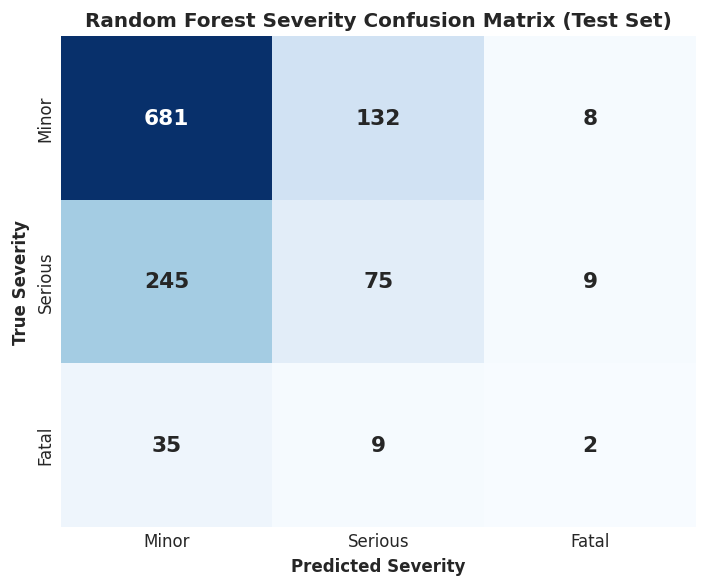

In [13]:
y_pred = full_pipeline.predict(X_test)
y_prob = full_pipeline.predict_proba(X_test)

classes = ["Minor", "Serious", "Fatal"]
acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("=" * 55)
print("OUT-OF-SAMPLE TEST EVALUATION METRICS")
print("=" * 55)
print(f"Overall Accuracy:  {acc:.4f} ({acc*100:.2f}%)")
print(f"Macro F1-Score:    {macro_f1:.4f}")
print(f"Weighted F1-Score: {weighted_f1:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred, labels=classes)

# Automated Checks: Validate Row Sums and Column Sums
cm_row_sums = cm.sum(axis=1)
cm_col_sums = cm.sum(axis=0)
for idx, cls in enumerate(classes):
    true_sup = int((y_test == cls).sum())
    assert cm_row_sums[idx] == true_sup, f"Row sum mismatch for {cls}: {cm_row_sums[idx]} != {true_sup}"
    pred_cnt = int((y_pred == cls).sum())
    assert cm_col_sums[idx] == pred_cnt, f"Col sum mismatch for {cls}: {cm_col_sums[idx]} != {pred_cnt}"
assert cm.sum() == len(y_test), "Total sum mismatch"
assert np.isclose(np.trace(cm) / cm.sum(), acc), "Accuracy mismatch with confusion matrix trace"
print("Automated Checks PASSED: Confusion-matrix row sums equal true class supports, column sums equal predicted counts, and total equals test set size.")

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
plt.title("Random Forest Severity Confusion Matrix (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Severity", fontweight="bold")
plt.ylabel("True Severity", fontweight="bold")
plt.tight_layout()
plt.show()

### 12. Feature Importance Analysis

Extract feature names from the fitted preprocessor and evaluate Gini importances.
*Important:* Importance scores describe internal tree split associations, not physical causal relationships.

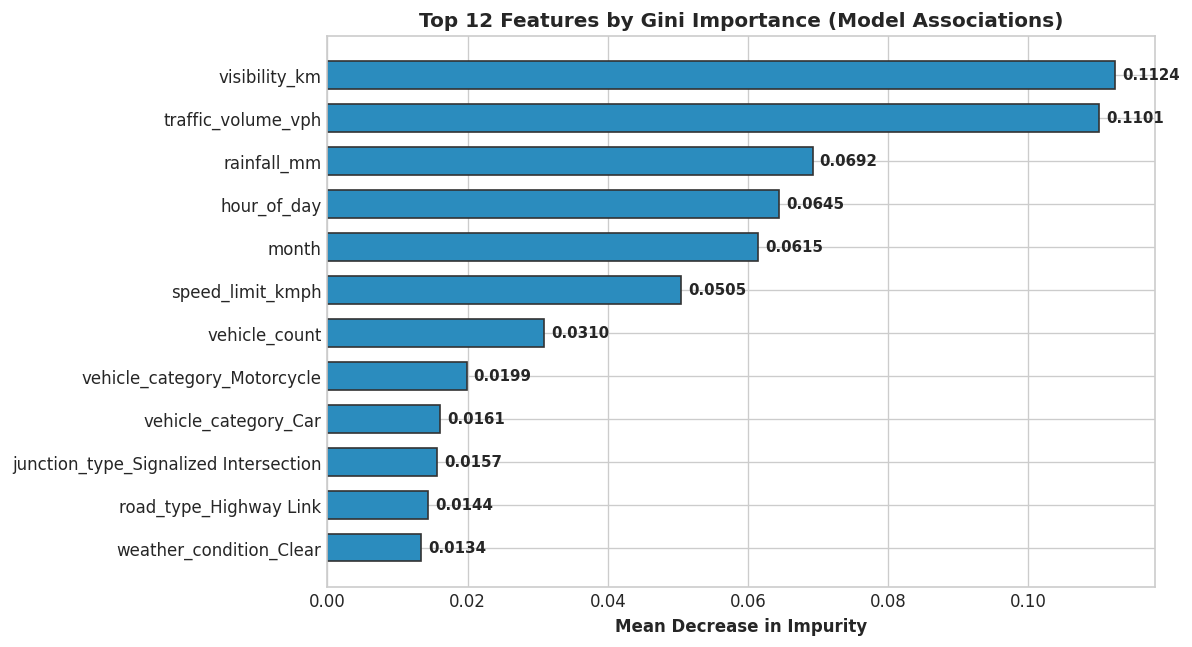

In [14]:
fitted_prep = full_pipeline.named_steps["preprocessor"]
cat_encoder = fitted_prep.named_transformers_["cat"].named_steps["onehot"]
all_feat_names = NUMERICAL_FEATURES + list(cat_encoder.get_feature_names_out(CATEGORICAL_FEATURES))
importances = full_pipeline.named_steps["classifier"].feature_importances_

fi_df = pd.DataFrame({
    "feature": all_feat_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

plt.figure(figsize=(10, 5.5))
top12 = fi_df.head(12).sort_values(by="importance", ascending=True)
plt.barh(top12["feature"], top12["importance"], color="#2b8cbe", edgecolor="#333", height=0.65)
plt.title("Top 12 Features by Gini Importance (Model Associations)", fontsize=12, fontweight="bold")
plt.xlabel("Mean Decrease in Impurity", fontweight="bold")
for idx, val in enumerate(top12["importance"]):
    plt.text(val + 0.001, idx, f"{val:.4f}", va="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

### 13. Key Insights and Strategic Recommendations

Synthesize evidence from empirical analysis and modeling:
1. **Severe Class Imbalance**: Minor incidents constitute 68.61%, Serious 27.53%, and Fatal-severity crashes 3.87% of recorded accidents.
2. **Corridor Profiling**: Central Market Junction leads total crash volume (445 incidents; 147 severe crashes), while East Lake Road exhibits the highest fatal crash count (24 fatal crashes; 7.50% fatal crash share of recorded accidents).
3. **Temporal Dynamics**: Volume peaks during commuter rush hours (08:00 and 18:00), but Night hours (21:00-04:59) experience the highest fatal crash proportion (4.71%).
4. **Adverse Weather Risks**: Dense Fog conditions escalate fatal crash proportion to 8.10% and combined severe crash share to 45.48%.
5. **Infrastructure Risks**: Highway Links carry a 6.03% fatal crash share (vs 2.68% on Collector Roads). Fatal crashes occurred on segments with a mean nominal speed limit of 48.4 km/h (vs 44.3 km/h for minor crashes).
6. **Vulnerable Road Users**: Motorcycles suffer a 5.06% fatal crash share and 30.65% serious injury share.
7. **Exposure Denominator Note**: These metrics represent crash counts and severity shares among recorded collisions, distinct from exposure-adjusted per-vehicle-km risk.

### 14. Final Conclusion

**Summary of Deliverables:**
- Cleaned integrated dataset of 5,976 records (`data/processed/cleaned_accidents.csv`) with zero key leakage.
- Machine learning pipeline (`models/road_safety_model.joblib`) with out-of-sample accuracy of 63.38% and Macro F1 of 0.3670.
- Interactive Streamlit dashboard (`app.py`) providing live risk scoring and filtering.
- Comprehensive 11-sheet workbook (`outputs/road_safety_analysis.xlsx`).
- Executive presentation (`outputs/business_insights_presentation.pptx`).

**Responsible Interpretation Disclaimer:**
As these data represent synthetic records without non-crash baseline traffic exposure, recommendations focus on targeted corridor infrastructure audits, dynamic adverse weather warnings, speed calming on high-speed links, and motorcycle safety enhancements.